# Screen Time Analysis

Estimated versus recorded daily smartphone use among B.Tech students.

The included dataset has 120 simulated records. Each row contains an estimate and seven daily readings for the same primary phone. The analysis cleans the data, explores estimation errors and runs a paired t-test.

Run the cells in order. To use survey responses, follow `docs/REAL_DATA_GUIDE.md` and change `CONFIG_PATH` below.

## 1. Load the data

pandas handles tables, NumPy supports numerical calculations, and SciPy provides statistical tests. The configuration selects the source file and output folder.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display, Markdown, Image

ROOT = Path.cwd().resolve()
while not (ROOT / 'src' / 'screentime').exists():
    if ROOT == ROOT.parent:
        raise RuntimeError('Open this notebook within the project folder.')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from screentime.pipeline import run_pipeline, parse_time

CONFIG_PATH = ROOT / 'config/simulated.json'  # Later: config/real.json
result = run_pipeline(CONFIG_PATH)
kind = result['config']['data_kind']
display(Markdown(f'**Active source: {kind}**'))
if kind == 'SIMULATED':
    display(Markdown('**Demonstration only — the outputs are not findings about real students.**'))
result['manifest']

**Active source: SIMULATED**

**Demonstration only — the outputs are not findings about real students.**

{'data_origin': 'SIMULATED',
 'source_file': 'data/simulated/screen_time_simulated.csv',
 'sha256': '2b93c54953ced72e693de17b3519a4100c8cee214badd7ff0e46dafb358d88b8',
 'generated_at_utc': '2026-10-17T18:45:30.072741+00:00',
 'submitted': 120,
 'included': 112,
 'excluded': 8,
 'possible_duplicate_rows': 0,
 'config': {'data_kind': 'SIMULATED',
  'input_csv': 'data/simulated/screen_time_simulated.csv',
  'output_dir': 'outputs/simulated',
  'alpha': 0.05,
  'column_map': {}},
 'versions': {'numpy': '2.3.5',
  'pandas': '2.2.3',
  'scipy': '1.18.1',
  'matplotlib': '3.11.2',
  'seaborn': '0.13.2'},
 'scope': 'Simulation demonstration, not student evidence'}

## 2. Inspect the source

Each row is one observation. `head()` previews the table and `shape` gives its row and column counts. Durations start as H:MM strings; confirmations are categorical fields.

In [2]:
raw = result['raw']
print('Rows and columns:', raw.shape)
display(raw.head())
display(raw.dtypes)

Rows and columns: (120, 14)


,consent,btech_enrolled,first_response,reference_end_date,estimated_daily_time,day_1_time,day_2_time,day_3_time,day_4_time,day_5_time,day_6_time,day_7_time,estimate_before_check,record_scope_confirmed
0,Yes,Yes,Yes,2026-10-13,7:45,9:45,7:05,,9:05,8:04,5:44,10:00,Yes,Yes
1,Yes,Yes,Yes,2026-10-14,5:00,4:14,24:15,4:24,8:04,5:24,5:27,5:50,Yes,Yes
2,Yes,Yes,Yes,2026-10-15,0:30,1:26,2:25,1:57,1:18,2:12,2:03,0:47,No,Yes
3,No,Yes,Yes,2026-10-16,5:15,7:10,4:15,5:08,5:09,4:53,5:12,5:58,Yes,Yes
4,Yes,No,Yes,2026-10-17,3:00,2:35,3:31,4:59,3:50,2:36,3:25,3:09,Yes,Yes


consent                   object
btech_enrolled            object
first_response            object
reference_end_date        object
estimated_daily_time      object
day_1_time                object
day_2_time                object
day_3_time                object
day_4_time                object
day_5_time                object
day_6_time                object
day_7_time                object
estimate_before_check     object
record_scope_confirmed    object
dtype: object

## 3. Validate and clean

Convert H:MM to minutes: 4:30 is 270 minutes. Missing or invalid values become NaN, not zero. Include a row only when the date, all eight durations and all five confirmations are valid.

The original CSV stays unchanged. IDs follow source-row order, and the audit records exclusions. Matching response patterns are flagged rather than automatically deleted. The simulation contains eight deliberately invalid records.

In [3]:
print('4:30 ->', parse_time('4:30'), 'minutes')
print('Invalid 24:15 ->', parse_time('24:15'))
audit = result['audited']
clean = result['clean']
display(audit[['participant_id', 'included', 'exclusion_reasons', 'possible_duplicate']].head(12))
print(f'Submitted={len(audit)}, included={len(clean)}, excluded={len(audit)-len(clean)}')
if clean.empty:
    raise RuntimeError('No usable pairs. Review audit.csv before any inferential analysis.')

4:30 -> 270.0 minutes
Invalid 24:15 -> nan


,participant_id,included,exclusion_reasons,possible_duplicate
0,SIM0001,False,invalid_or_missing_daily_record,False
1,SIM0002,False,invalid_or_missing_daily_record,False
2,SIM0003,False,estimate_before_check_not_yes,False
3,SIM0004,False,consent_not_yes,False
4,SIM0005,False,btech_enrolled_not_yes,False
5,SIM0006,False,first_response_not_yes,False
6,SIM0007,False,invalid_reference_end_date,False
7,SIM0008,False,record_scope_confirmed_not_yes,False
8,SIM0009,True,,False
9,SIM0010,True,,False


Submitted=120, included=112, excluded=8


## 4. Calculate estimation errors

Let $E_i$ be estimated daily minutes and $R_i$ the average of seven recorded daily totals. The signed error is $d_i=R_i-E_i$: positive means underestimation, negative means overestimation. Absolute error $|d_i|$ measures the size of the mismatch.

`axis=1` averages across each row; `skipna=False` prevents an incomplete week from being averaged. Seven days from one participant still form one observation.

In [4]:
day_columns = [f'day_{i}_minutes' for i in range(1, 8)]
recorded_check = clean[day_columns].mean(axis=1, skipna=False)
difference_check = recorded_check - clean['estimated_daily_minutes']
assert np.allclose(recorded_check, clean['recorded_daily_minutes'])
assert np.allclose(difference_check, clean['signed_error_minutes'])
display(clean[['participant_id', 'estimated_daily_minutes', 'recorded_daily_minutes',
               'signed_error_minutes', 'absolute_error_minutes']].head())

,participant_id,estimated_daily_minutes,recorded_daily_minutes,signed_error_minutes,absolute_error_minutes
0,SIM0009,195.0,267.142857,72.142857,72.142857
1,SIM0010,225.0,280.428571,55.428571,55.428571
2,SIM0011,180.0,329.285714,149.285714,149.285714
3,SIM0012,375.0,491.285714,116.285714,116.285714
4,SIM0013,420.0,430.285714,10.285714,10.285714


## 5. Descriptive statistics

`describe()` gives the mean, median, sample standard deviation and quartiles. Mean signed error measures net bias; mean absolute error measures error size. Errors of −60 and +60 cancel to zero mean bias but give a mean absolute error of 60 minutes.

In [5]:
display(result['descriptive'].round(2))
display(clean['perception_group'].value_counts().rename('students').to_frame())

,data_origin,variable,unit,count,mean,std,min,25%,50%,75%,max
0,SIMULATED,estimated_daily_minutes,minutes/day,112.0,269.20,133.42,0.00,165.00,255.00,345.00,585.00
1,SIMULATED,recorded_daily_minutes,minutes/day,112.0,291.68,112.84,102.00,212.07,283.93,353.04,635.86
2,SIMULATED,signed_error_minutes,minutes/day,112.0,22.48,72.17,-228.14,-23.07,28.00,64.68,217.29
3,SIMULATED,absolute_error_minutes,minutes/day,112.0,59.42,46.44,0.71,25.71,45.57,88.18,228.14


,students
perception_group,
Underestimated >30 min,53
Within 30 min,37
Overestimated >30 min,22


## 6. Exploratory plots

In the scatterplot, points above the equality line show underestimation. The histogram shows the direction and spread of errors. The ±30-minute grouping is a descriptive convention, not a health threshold. Correlation between the measurements does not establish agreement.

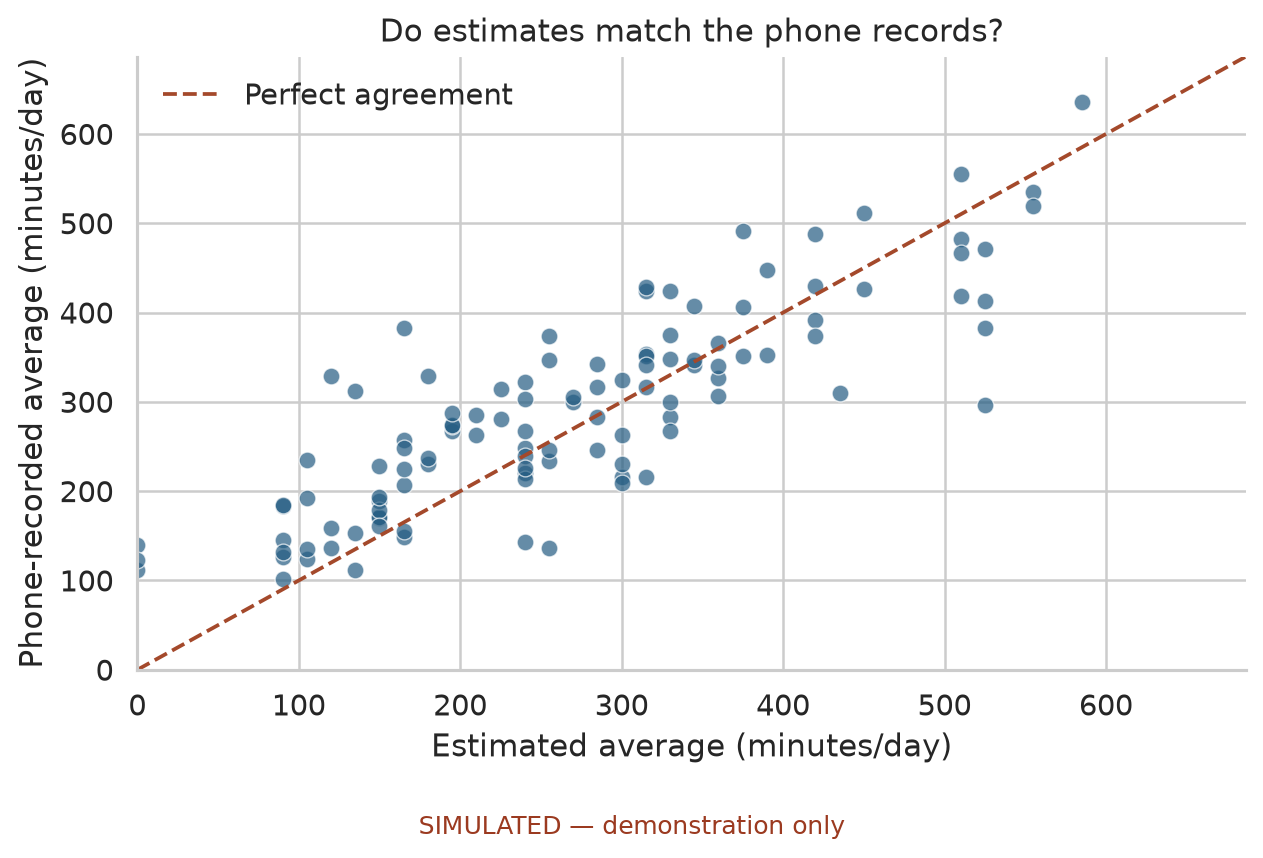

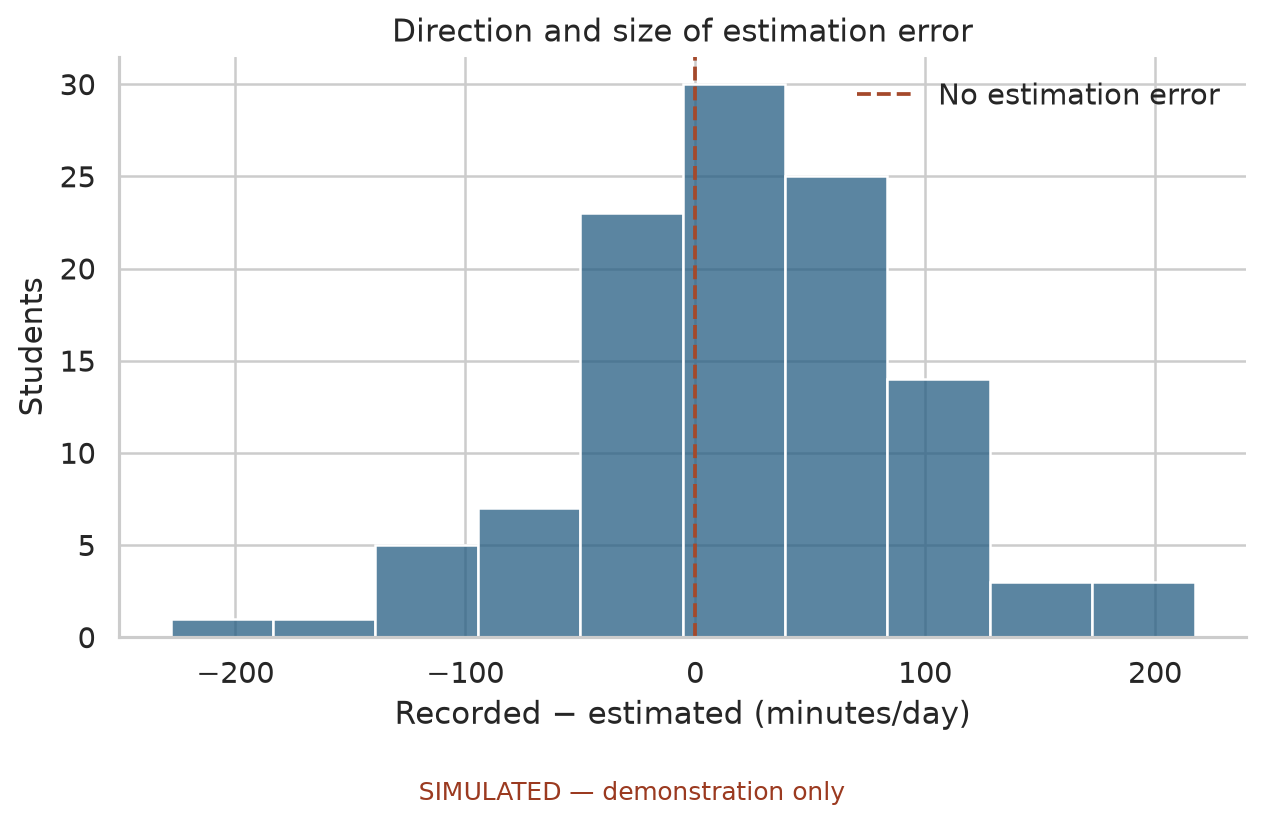

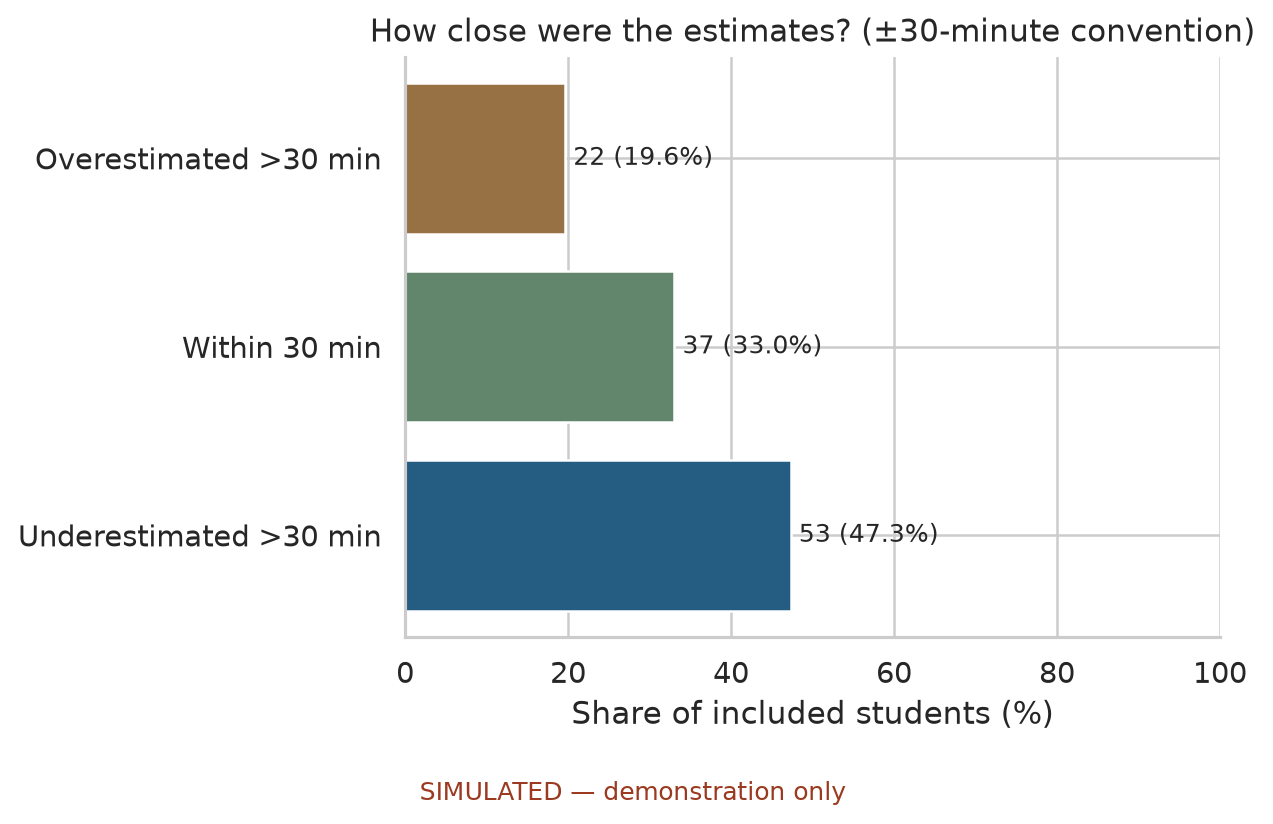

In [6]:
for filename in ['01_estimated_vs_recorded.png', '02_signed_errors.png', '03_accuracy_groups.png']:
    display(Image(filename=str(result['output_dir'] / 'figures' / filename), width=700))

## 7. Hypothesis and assumptions

Test $H_0:\mu_d=0$ against $H_1:\mu_d\ne0$, using $\alpha=0.05$. The question concerns average bias, not the accuracy of every estimate.

The paired test assumes independent participant differences and a sufficiently well-behaved distribution of differences. Inspect the Q–Q plot and extreme values. Sampling and recording quality also affect interpretation.

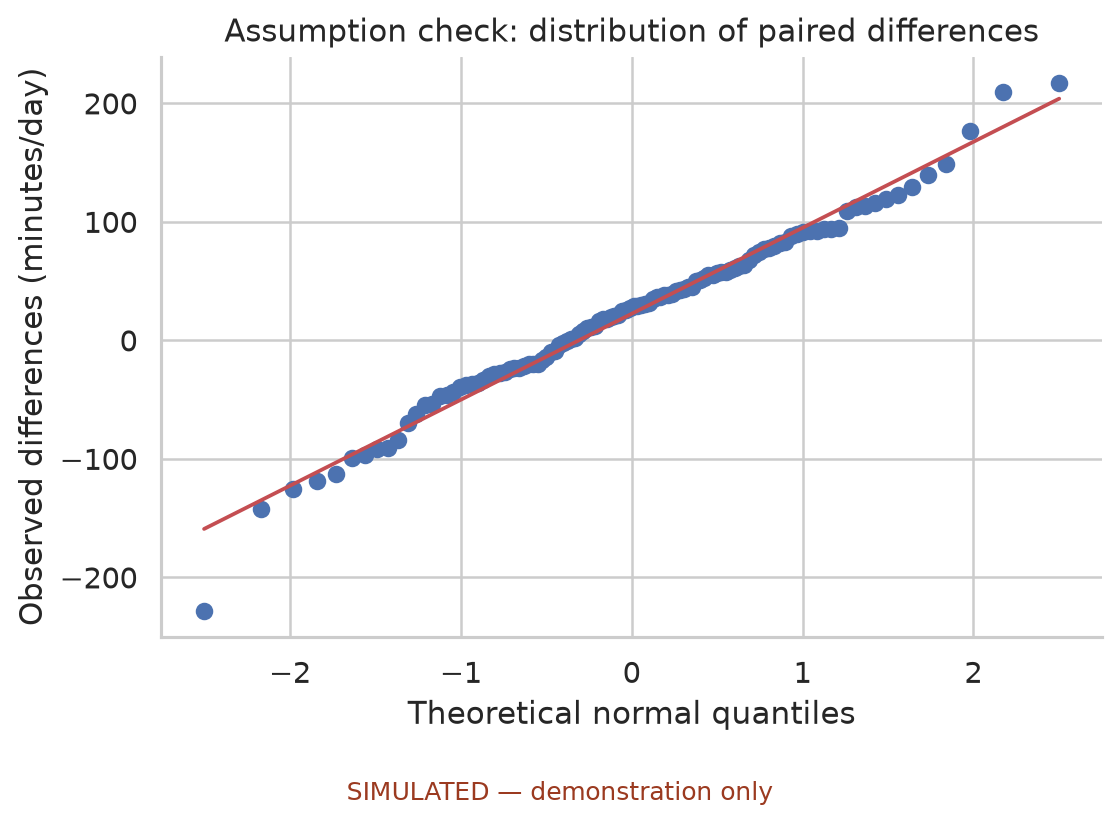

['3 differences outside Tukey fences: inspect, do not automatically remove.']

In [7]:
qq = result['output_dir'] / 'figures' / '04_difference_qq.png'
if qq.exists():
    display(Image(filename=str(qq), width=650))
else:
    print('Q–Q plot unavailable for an insufficient or constant set of differences.')
result['statistics']['warnings']

## 8. Paired t-test

$$t=\frac{\bar d}{s_d/\sqrt{n}},\qquad df=n-1.$$

Use the sample SD of the differences (`ddof=1`). Twice the upper-tail probability at $|t|$ gives the two-sided p-value. The confidence interval is the mean difference plus or minus the critical t-value times the standard error.

`ttest_rel(a, b)` uses matched observations and calculates a minus b. Recorded time goes first to preserve the sign convention. The calculations below check the formula against SciPy.

In [8]:
d = clean['signed_error_minutes'].to_numpy()
n = len(d)
if n >= 2 and np.std(d, ddof=1) > 0:
    mean_d = np.mean(d)
    sd_d = np.std(d, ddof=1)
    se = sd_d / np.sqrt(n)
    t_manual = mean_d / se
    p_manual = 2 * stats.t.sf(abs(t_manual), df=n-1)
    alpha = result['config']['alpha']
    critical = stats.t.ppf(1-alpha/2, df=n-1)
    ci_manual = (mean_d-critical*se, mean_d+critical*se)
    test = stats.ttest_rel(clean['recorded_daily_minutes'], clean['estimated_daily_minutes'],
                           alternative='two-sided', nan_policy='raise')
    assert np.isclose(test.statistic, t_manual)
    assert np.isclose(test.pvalue, p_manual)
    display(pd.DataFrame({'quantity': ['n', 'mean difference', 'SD of differences', 'SE', 't', 'df', 'p', 'CI low', 'CI high'],
                          'value': [n, mean_d, sd_d, se, t_manual, n-1, p_manual, *ci_manual]}))
else:
    print('An ordinary paired t-test cannot be computed for this dataset.')

,quantity,value
0,n,112.000000
1,mean difference,22.484694
2,SD of differences,72.174360
3,SE,6.819836
4,t,3.296955
5,df,111.000000
6,p,0.001313
7,CI low,8.970734
8,CI high,35.998654


## 9. Results

Interpret the p-value alongside the mean error and confidence interval. A small p-value is evidence against zero mean difference under the test assumptions; it is not the probability that the null hypothesis is true.

The current results describe simulated data and reflect the generator's assumptions. They do not establish how actual B.Tech students estimate their usage.

In [9]:
display(Markdown((result['output_dir'] / 'RUN_SUMMARY.md').read_text()))

# SIMULATED: screen-time analysis

**SIMULATED DATA — no students were surveyed; numerical results demonstrate the workflow only.**

Submitted: 120. Included: 112. Excluded: 8.
Exclusion reason counts may overlap. IDs refer to rows of this frozen source file.

Mean recorded-minus-estimated difference: 22.48 minutes/day.
Mean absolute error: 59.42 minutes/day.
Paired t(111) = 3.2970; two-sided p = 0.00131324.
95% confidence interval: [8.97, 36.00] minutes/day.
Mechanical test decision: reject H0 at alpha=0.05. Review assumptions before interpretation.

Positive differences mean underestimation. Zero mean bias does not establish individual accuracy.
No causal, addiction, or academic-performance conclusion is supported.

- 3 differences outside Tukey fences: inspect, do not automatically remove.


## 10. Using survey data

Use the questions in `docs/SURVEY_SCRIPT.md` and save the export under `data/raw/`. Map its headings in `config/real.json`, change `CONFIG_PATH`, then restart and run all cells.

Review the new exclusions, plots and test results before updating the report. Keep real and simulated records separate. Real exports and generated outputs are ignored by Git; clear any real participant data from notebook outputs before committing.